# Results

With JupyterBook it is possible to make your narrative and data-analysis available in a single file, through Jupyter Notebooks. It is even possible to create interactive materials using widgets on the website, but leave them out in the PDF version (using tags). To run the code below, click the ![](figures/on.png) icon in the top right corner. This will connect with a kernel. If the kernel is loaded, click ![](figures/play.png) to run the code. 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
from matplotlib.gridspec import GridSpec

np.random.seed(42)

# Data
x = np.linspace(0, 20, 7)
y = 2.03 * x + np.random.normal(0, 3, len(x))

# range for a
a_min, a_max, steps = 0, 3, 50
a_vals = np.linspace(a_min, a_max, 50)

# make chi-squared curve
chi2_vals = np.array([np.sum((y - a * x)**2) for a in a_vals])
a_opt = a_vals[np.argmin(chi2_vals)]
saved = False # for saving the figure only once

def update(a):
    # Model and residual
    y_model = a * x
    residuen = y - y_model
    chi2 = np.sum(residuen**2)

    fig = plt.figure(figsize=(11, 6))
    gs = GridSpec(2, 2, width_ratios=[2, 1.4], height_ratios=[3, 1], figure=fig)

    ax_main = fig.add_subplot(gs[0, 0])
    ax_res = fig.add_subplot(gs[1, 0], sharex=ax_main)
    ax_chi2 = fig.add_subplot(gs[:, 1])

    # --- upperleft plot: data + model ---
    ax_main.plot(x, y, 'k.', markersize=10, label='Data')
    ax_main.plot(x, y_model, 'r--', linewidth=2, label=fr'Model: $y = {a:.2f}x$')
    ax_main.set_ylabel('y')
    ax_main.set_title('Data and model')
    ax_main.legend()
    ax_main.grid(alpha=0.3)

    # --- bottom left plot: residuals ---
    ax_res.axhline(0, color='gray', linestyle=':', linewidth=1)
    ax_res.plot(x, residuen, 'bo', markersize=7)
    ax_res.vlines(x, 0, residuen, color='b', alpha=0.6)
    ax_res.set_xlabel('x')
    ax_res.set_ylabel('residuals')
    ax_res.set_title('Residuals')
    ax_res.grid(alpha=0.3)

    # --- right plot: chi-squared-curve ---
    ax_chi2.plot(a_vals, chi2_vals, 'k-', linewidth=2)
    ax_chi2.plot(a, chi2, 'ro', markersize=9, label=fr'$\chi^2 = {chi2:.2f}$')
    ax_chi2.axvline(a, color='r', linestyle='--', alpha=0.5)
    ax_chi2.set_xlabel('coefficient a')
    ax_chi2.set_ylabel(r'$\chi^2 = \sum (y - ax)^2$')
    ax_chi2.set_title(r'$\chi^2$ as a function of a')
    ax_chi2.legend()
    ax_chi2.grid(alpha=0.3)

    plt.tight_layout()

    global saved
    if abs(a - a_opt) < (a_max-a_min)/steps and not saved:
        # fig.savefig("figures/chi2_fit.eps")
        # fig.savefig("figures/chi2_fit.png", dpi=450)
        saved = True
    plt.show()

interact(
    update,
    a=widgets.FloatSlider(min=a_min, max=a_max, step=(a_max - a_min) / steps, value=1, description='a')
)


+++{"no-pdf": true}
```{tip} Interactive
Run the on button at the top right corner and then the play button to run the code cell and interact with the model.
```
+++

{numref}`chi2_fit` shows the results of fitting our linear model to the data. Parameter $a$ is optimal when the chi-squared curve is at its minimum, which corresponds to the smallest residuals and the best match between model and data. 

```{figure} figures/chi2_fit.*
:label: chi2_fit
:alt: Chi-squared fit, linear trend, with residuals and chi-squared curve.

Fitting our data to a linear model with a single parameter $a$. The optimal value of $a$ is found when the chi-squared curve (bottom) is at its minimum. The residuals (top right) are smallest at this point, and the model (top left) best matches the data.
```

So i should be able to add some tekst and perhaps even a formula with ref here. lets ref to my favorite (Newton). {numref}`eq {number} <Newton>` and hope this works. 

Now that this works i want to add another piece of code. numpy and matplot lib should already be imported

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
from matplotlib.gridspec import GridSpec


def simulate(b=1):
    m = 1
    N = 1000

    ti = 0
    tf = 10
    t = np.linspace(ti, tf, N)
    dt = t[1] - t[0]

    F = np.exp(-b*t/10)  # Force as a function of time
    a = F/m



    # Velocity
    vi = 0
    v = np.zeros(N)
    v[0] = vi

    for i in range(1, N):
        v[i] = v[i-1] + a[i-1] * dt

    # Position
    xi = 0
    x = np.zeros(N)
    x[0] = xi

    for i in range(1, N):
        x[i] = x[i-1] + v[i-1] * dt

    # Plot results
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(t, v, 'b-', label='Velocity')
    plt.xlabel('Time (s)')
    plt.ylabel('Velocity (m/s)')
    plt.title(f'Velocity vs Time (F = N)')
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(t, x, 'r-', label='Position')
    plt.xlabel('Time (s)')
    plt.ylabel('Position (m)')
    plt.title(f'Position vs Time (F = N)')
    plt.grid()

    plt.tight_layout()
    plt.show()

# Interactive force slider
interact(
    simulate,
    b=widgets.FloatSlider(
        value=1,
        min=0,
        max=10,
        step=1,
        description='B',
        continuous_update=True
    )
)

Now that i know this works lets try something. I was interested at how in optics the phase shift actually matters. So lets have a look at that with a virtual double slit experiment. 

sampling condition fulfilled


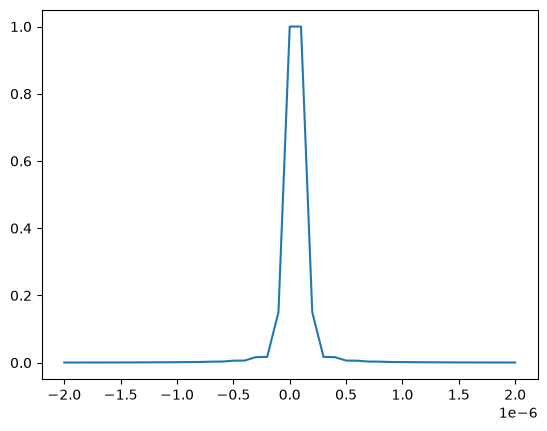

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
L = 100*10**-6
x = np.linspace(-L/2,L/2,N,endpoint = False)
dx = x[1] - x[0]
fx = np.fft.fftfreq(N,dx)


#otf
w = 25*10**-3 #radius aperture
wl = 633*10**-9 #wavelength
fn = 1/(2*dx) #frequency nyquist
si = 40*10**-3 #image dist

if (fn >= 2*w/(wl*si)):
    print("sampling condition fulfilled")

otf = np.zeros(N)
otf = np.where(fx < w/wl*si,1,0)





#create opject U
Uobj = np.zeros(N,dtype = complex)
offset = 1
phase = 0.5*np.pi
Uobj[N//2] = 1
Uobj[N//2+offset] = np.exp(1j*phase)

U = np.fft.fftshift(np.fft.fft(np.fft.fftshift(Uobj)))
U = U*otf
Uf = np.fft.fftshift(np.fft.ifft(np.fft.fftshift(U)))

I = np.abs(Uf)**2
I = I/np.max(I)

plt.plot(x[N//2 - 20:N//2+ 20+offset],I[N//2 - 20:N//2+ 20+offset])




  
